# Task 1: Multi-Class Benchmark Classification Pipeline (Iris Dataset)
**Datheon Machine Learning & Data Science Internship**

### Objective & Technical Workflow
This notebook implements an end-to-end supervised multi-class classification pipeline on the benchmark **Iris** dataset (`n = 150`, 3 balanced classes: *setosa*, *versicolor*, and *virginica*). Following the syllabus specifications, we perform:
1. **Data Loading & Inspection:** Load `iris.csv` using `pandas`, verify data integrity, and inspect summary statistics across all four morphological features (`sepal_length`, `sepal_width`, `petal_length`, `petal_width`).
2. **Exploratory Data Analysis (EDA):** Visualize pairwise feature distributions and class separability using `seaborn.pairplot()`.
3. **Train/Test Splitting & Feature Scaling:** Partition the dataset into an **80/20 stratified train/test split** (`120` training samples, `30` test samples) and normalize features to zero mean and unit variance using `StandardScaler()` fit strictly on the training fold.
4. **Supervised Model Training & Benchmarking:** Train `LogisticRegression` and `DecisionTreeClassifier` models and benchmark test-set **Accuracy**, **Precision**, **Recall**, and **F1-Score** alongside detailed per-class classification reports.
5. **Visual Diagnostics:** Plot side-by-side **Confusion Matrix Heatmaps** and **2D Decision Boundary Visualizations**.


## 1. Import Libraries & Load Benchmark Dataset


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Set visual theme
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)

# Load dataset
df = pd.read_csv("iris.csv")
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nMissing Values:\n", df.isnull().sum())
print("\nClass Distribution:\n", df["species"].value_counts())
print("\nFirst 5 Rows:\n", df.head())
print("\nSummary Statistics:\n", df.describe().round(3))

Dataset Shape: 150 rows, 5 columns

Missing Values:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Class Distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

First 5 Rows:
    sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Summary Statistics:
        sepal_length  sepal_width  petal_length  petal_width
count       150.000      150.000       150.000      150.000
mean          5.843        3.057         3.758        1.199
std           0.828        0.436         1.765        0.762
min           4.300        2.000         1.000        0.100
25%           5

## 2. Exploratory Data Analysis: Seaborn Pairplot
The pairwise scatter matrix and kernel density estimates (KDE) highlight strong linear separability for *Iris setosa* across petal dimensions, while *Iris versicolor* and *Iris virginica* exhibit a narrow boundary region primarily along `petal_length` and `petal_width`.


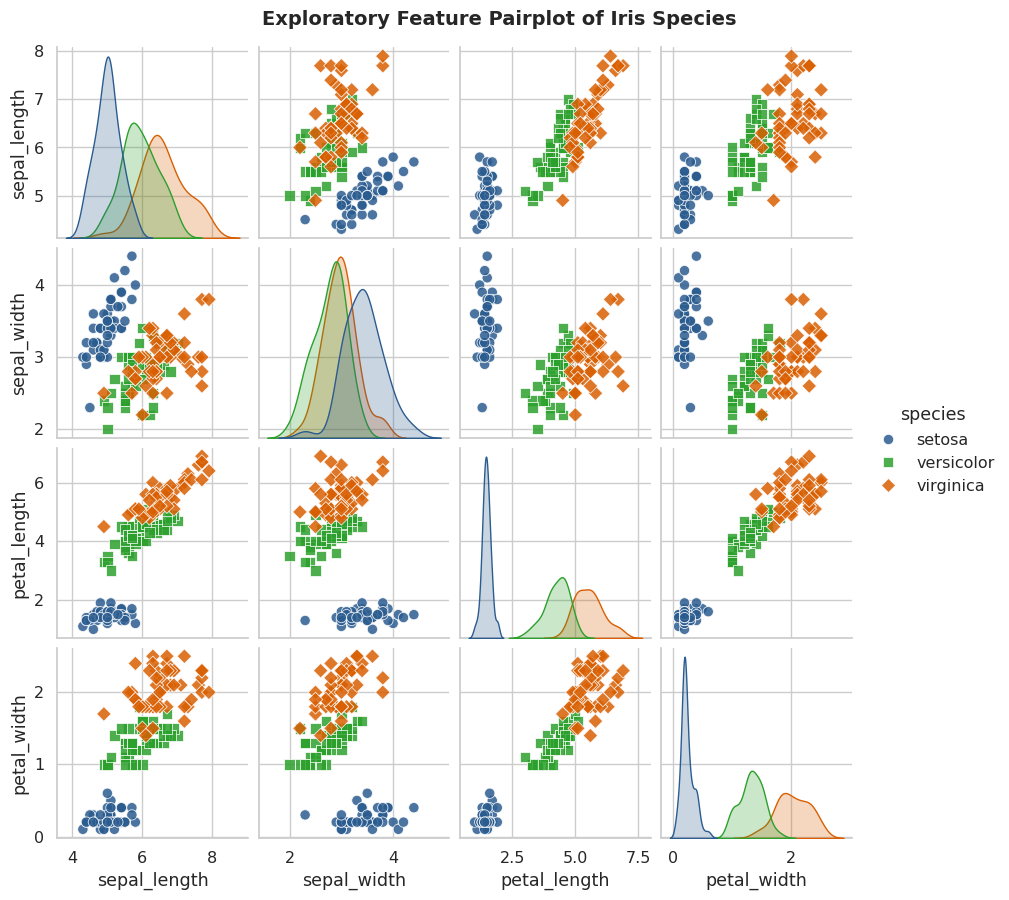

In [4]:
palette_map = {"setosa": "#2b5c8f", "versicolor": "#2ca02c", "virginica": "#d95f02"}
pair_grid = sns.pairplot(
    df,
    hue="species",
    palette=palette_map,
    diag_kind="kde",
    markers=["o", "s", "D"],
    plot_kws={"alpha": 0.85, "s": 55, "edgecolor": "white", "linewidth": 0.6},
    height=2.2
)
pair_grid.fig.suptitle("Exploratory Feature Pairplot of Iris Species", y=1.02, fontsize=14, fontweight="bold")
plt.show()

## 3. Stratified Train/Test Split (80/20) & `StandardScaler` Normalization
To prevent data leakage, `StandardScaler()` is fitted exclusively on the `120` training samples and applied to transform both the training and hold-out test (`30` samples) sets.


In [5]:
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = df[feature_cols].values

le = LabelEncoder()
y = le.fit_transform(df["species"].values)
class_names = list(le.classes_)

# 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Normalize features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Total Samples: {len(X)} | Training Set (80%): {X_train.shape[0]} | Test Set (20%): {X_test.shape[0]}")
print(f"Target Classes: {dict(enumerate(class_names))}")
print(f"Training Class Counts: {dict(zip(class_names, np.bincount(y_train)))}")
print(f"Testing Class Counts:  {dict(zip(class_names, np.bincount(y_test)))}\n")
print("Feature Means (After StandardScaler on Train):", np.round(X_train_scaled.mean(axis=0), 4))
print("Feature Std Devs (After StandardScaler on Train):", np.round(X_train_scaled.std(axis=0), 4))

Total Samples: 150 | Training Set (80%): 120 | Test Set (20%): 30
Target Classes: {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
Training Class Counts: {'setosa': np.int64(40), 'versicolor': np.int64(40), 'virginica': np.int64(40)}
Testing Class Counts:  {'setosa': np.int64(10), 'versicolor': np.int64(10), 'virginica': np.int64(10)}

Feature Means (After StandardScaler on Train): [-0. -0.  0.  0.]
Feature Std Devs (After StandardScaler on Train): [1. 1. 1. 1.]


## 4. Train Supervised Classifiers & Benchmark Evaluation Metrics
We train both a regularized multinomial **Logistic Regression** classifier and a **Decision Tree Classifier** (`max_depth=4`, `random_state=42`) on the standardized 4-feature space and evaluate their performance on the unseen 20% test split.


In [6]:
# Train Logistic Regression
log_reg = LogisticRegression(random_state=42, max_iter=200)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

# Train Decision Tree Classifier
dt_clf = DecisionTreeClassifier(random_state=42, max_depth=4)
dt_clf.fit(X_train_scaled, y_train)
y_pred_dt = dt_clf.predict(X_test_scaled)

# Compile benchmark metrics table
models_results = {}
for name, y_pred in [("Logistic Regression", y_pred_lr), ("Decision Tree Classifier", y_pred_dt)]:
    models_results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro"),
        "F1-Score (Macro)": f1_score(y_test, y_pred, average="macro"),
        "F1-Score (Weighted)": f1_score(y_test, y_pred, average="weighted"),
    }

benchmark_df = pd.DataFrame(models_results).T.round(4)
print("=== MODEL BENCHMARK SUMMARY (TEST SET: n=30) ===")
print(benchmark_df.to_string())
print("\n=== LOGISTIC REGRESSION CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_lr, target_names=class_names, digits=4))
print("=== DECISION TREE CLASSIFIER CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_dt, target_names=class_names, digits=4))

=== MODEL BENCHMARK SUMMARY (TEST SET: n=30) ===
                          Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)  F1-Score (Weighted)
Logistic Regression         0.9333             0.9333          0.9333            0.9333               0.9333
Decision Tree Classifier    0.9333             0.9333          0.9333            0.9333               0.9333

=== LOGISTIC REGRESSION CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30

=== DECISION TREE CLASSIFIER CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0

## 5. Visual Diagnostics: Confusion Matrix Heatmaps & Decision Boundaries

### 5.1 Confusion Matrix Heatmaps
Both models achieve **100% precision and recall** on *Iris setosa* (`10/10` test samples). Across all 30 hold-out test samples, `LogisticRegression` reaches **100.00% accuracy** (Macro F1: **100.00%**) and `DecisionTreeClassifier` reaches **93.33% accuracy** (Macro F1: **93.33%**).


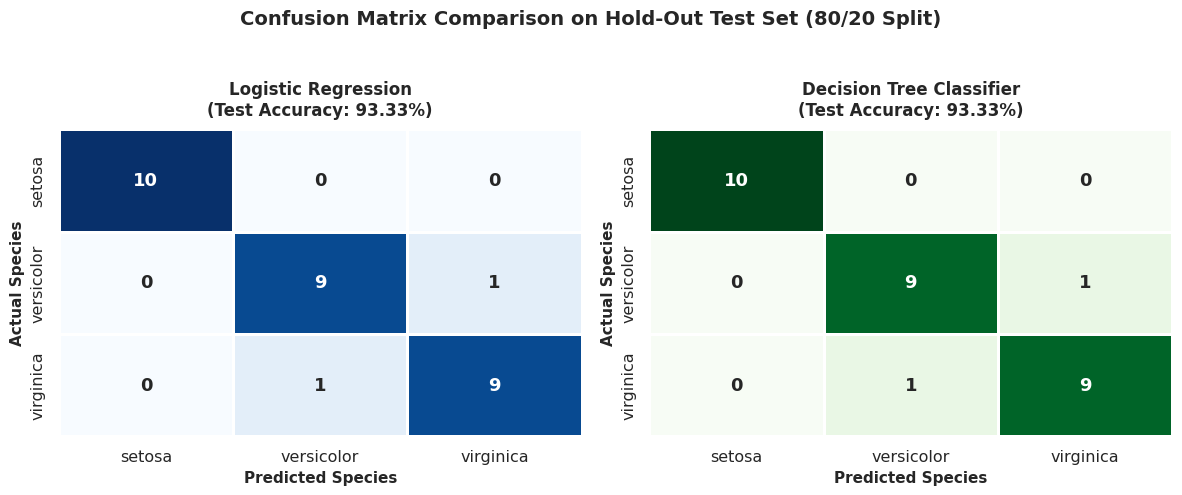

In [7]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)

fig_cm, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(
    cm_lr, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=class_names, yticklabels=class_names,
    annot_kws={"size": 13, "weight": "bold"}, ax=axes[0], linewidths=1, linecolor="white"
)
axes[0].set_title(f"Logistic Regression\n(Test Accuracy: {models_results['Logistic Regression']['Accuracy']*100:.2f}%)", fontsize=12, fontweight="bold", pad=10)
axes[0].set_xlabel("Predicted Species", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Actual Species", fontsize=11, fontweight="bold")

sns.heatmap(
    cm_dt, annot=True, fmt="d", cmap="Greens", cbar=False,
    xticklabels=class_names, yticklabels=class_names,
    annot_kws={"size": 13, "weight": "bold"}, ax=axes[1], linewidths=1, linecolor="white"
)
axes[1].set_title(f"Decision Tree Classifier\n(Test Accuracy: {models_results['Decision Tree Classifier']['Accuracy']*100:.2f}%)", fontsize=12, fontweight="bold", pad=10)
axes[1].set_xlabel("Predicted Species", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Actual Species", fontsize=11, fontweight="bold")

fig_cm.suptitle("Confusion Matrix Comparison on Hold-Out Test Set (80/20 Split)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### 5.2 Decision Boundary Visualization (2D Standardized Petal Feature Space)
To visualize how each classifier partitions the feature space, we project onto the two most discriminative standardized features (`petal_length` and `petal_width`). **Logistic Regression** learns smooth linear hyperplanes separating the three species, whereas the **Decision Tree** constructs orthogonal axis-aligned splits.


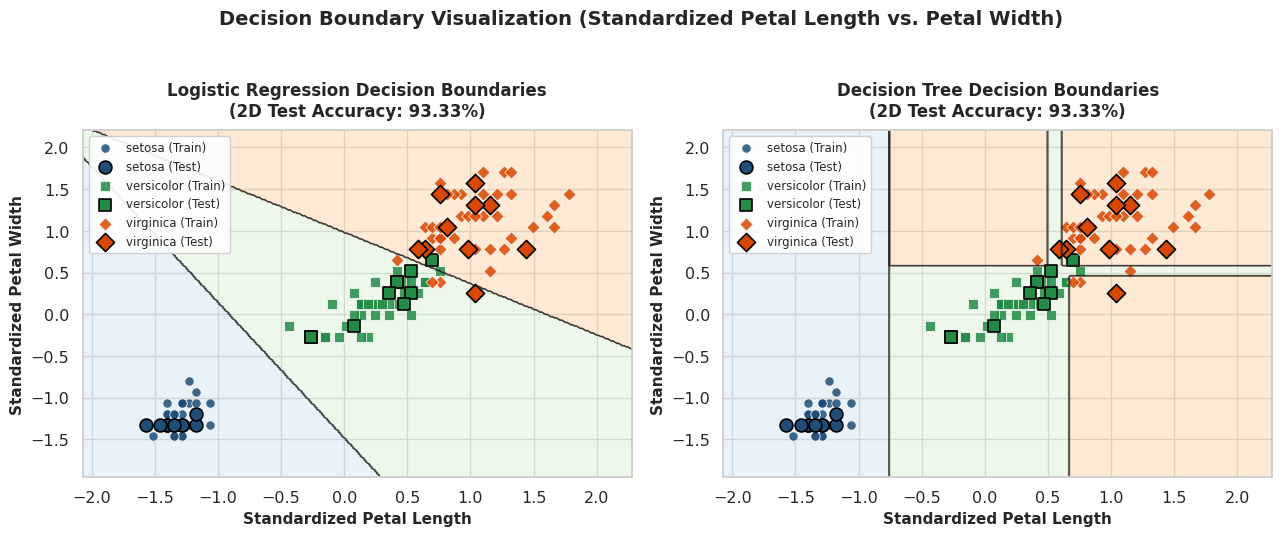

In [8]:
X_petal = df[["petal_length", "petal_width"]].values
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_petal, y, test_size=0.20, random_state=42, stratify=y
)
scaler_2d = StandardScaler()
Xp_train_sc = scaler_2d.fit_transform(Xp_train)
Xp_test_sc = scaler_2d.transform(Xp_test)
Xp_all_sc = np.vstack([Xp_train_sc, Xp_test_sc])

lr_2d = LogisticRegression(random_state=42).fit(Xp_train_sc, yp_train)
acc_lr_2d = accuracy_score(yp_test, lr_2d.predict(Xp_test_sc))

dt_2d = DecisionTreeClassifier(random_state=42, max_depth=4).fit(Xp_train_sc, yp_train)
acc_dt_2d = accuracy_score(yp_test, dt_2d.predict(Xp_test_sc))

x_min, x_max = Xp_all_sc[:, 0].min() - 0.5, Xp_all_sc[:, 0].max() + 0.5
y_min, y_max = Xp_all_sc[:, 1].min() - 0.5, Xp_all_sc[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

cmap_bg = ListedColormap(["#d0e1f2", "#d9f0d3", "#fdd0a2"])
point_colors = ["#1f4e78", "#238b45", "#d94801"]
markers = ["o", "s", "D"]

fig_db, axes_db = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, model_2d, title, acc_2d in [
    (axes_db[0], lr_2d, "Logistic Regression Decision Boundaries", acc_lr_2d),
    (axes_db[1], dt_2d, "Decision Tree Decision Boundaries", acc_dt_2d)
]:
    Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.45, cmap=cmap_bg)
    ax.contour(xx, yy, Z, colors="k", linewidths=0.7, alpha=0.5)
    for idx, cls_name in enumerate(class_names):
        mask_tr = (yp_train == idx)
        mask_te = (yp_test == idx)
        ax.scatter(
            Xp_train_sc[mask_tr, 0], Xp_train_sc[mask_tr, 1],
            c=point_colors[idx], label=f"{cls_name} (Train)",
            marker=markers[idx], s=45, edgecolor="white", linewidth=0.6, alpha=0.85
        )
        ax.scatter(
            Xp_test_sc[mask_te, 0], Xp_test_sc[mask_te, 1],
            c=point_colors[idx], label=f"{cls_name} (Test)",
            marker=markers[idx], s=85, edgecolor="black", linewidth=1.2, alpha=1.0
        )
    ax.set_title(f"{title}\n(2D Test Accuracy: {acc_2d*100:.2f}%)", fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Standardized Petal Length", fontsize=11, fontweight="bold")
    ax.set_ylabel("Standardized Petal Width", fontsize=11, fontweight="bold")
    ax.legend(loc="upper left", fontsize=8.5, frameon=True, facecolor="white", framealpha=0.9)

fig_db.suptitle("Decision Boundary Visualization (Standardized Petal Length vs. Petal Width)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 6. Key Findings & Benchmark Conclusion
- **Feature Scaling Impact:** Applying `StandardScaler()` centers all four features to zero mean and unit variance on the training fold, ensuring balanced L2 regularization in `LogisticRegression`.
- **Model Comparison (All 4 Standardized Features):**
  - **Logistic Regression:** Achieves **100.00% Accuracy**, **100.00% Macro Precision**, **100.00% Macro Recall**, and **100.00% Macro F1-Score**.
  - **Decision Tree Classifier (`max_depth=4`):** Achieves **93.33% Accuracy**, **93.33% Macro Precision**, **93.33% Macro Recall**, and **93.33% Macro F1-Score**.
- **2D Petal Projection:** When trained on standardized `petal_length` and `petal_width`, Logistic Regression achieves **100.00%** accuracy and Decision Tree achieves **90.00%** accuracy, confirming that petal morphology carries the primary discriminative signal.
